# Yell Commander · Fase 1
## Ajuste fino de DistilBERT en español

Revisión del dataset, entrenamiento supervisado y validación del prototipo textual. Conservamos A (BiGRU desde cero) y B (Qwen local por prompting). C adapta un encoder DistilBERT preentrenado a intención, acción y etiquetas BIO del mismo contrato JSON v1.

Ejecuta las celdas en orden con el Python de `.venv`. Para volver a entrenar cambia `REENTRENAR_C` a `True` en la configuración. El entrenamiento usa el mismo código que el comando de consola.

In [2]:
from pathlib import Path
import json, os, sys

inicio = Path.cwd().resolve()
nlp = next((p / 'AI NLP' for p in (inicio, *inicio.parents) if (p / 'AI NLP/yell').is_dir()), None)
if nlp is None:
    raise FileNotFoundError('Abre el cuaderno dentro de la carpeta del proyecto.')
sys.path.insert(0, str(nlp))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'

from yell.contract import INTENTS, UNITS
from yell.evaluate import evaluate_rows, evaluate_text, get_model
from yell.phase1_data import audit_phase1, build_phase1
from yell.train_transfer import TrainingConfig, train
from IPython.display import display, Markdown, JSON

resultados = nlp.parent / 'Documentacion/results/fase1'
print(sys.executable, '|', nlp.name)

c:\Users\aaran\Documents\Semestre 2-26\SIS421\SIS421_02-2026\NLP\Proyecto final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\aaran\Documents\Semestre 2-26\SIS421\SIS421_02-2026\NLP\Proyecto final\.venv\Scripts\python.exe | AI NLP


## 1. Inspeccionar y validar el dataset

Los ejemplos sintéticos anotados y las variaciones de cada familia se agrupan antes de asignarlos a entrenamiento, validación o prueba. La prueba v1 conserva las frases históricas. La prueba v2 agrega formulaciones nuevas, charla cotidiana, arengas, negaciones y cambios de acentuación o puntuación.

In [3]:
splits = build_phase1()
auditoria = audit_phase1(splits)
for nombre, dato in auditoria.items():
    print(f"{nombre:8s} · {dato['samples']:4d} frases · {dato['families']:3d} familias · {dato['intents']}")
display(JSON(splits['train'][0]))

train    · 2176 frases · 248 familias · {'orden': 1698, 'motivacion': 106, 'charla': 106, 'desconocido': 266}
val      ·  219 frases ·  88 familias · {'orden': 185, 'motivacion': 11, 'charla': 11, 'desconocido': 12}
test_v1  ·  172 frases ·  46 familias · {'orden': 159, 'motivacion': 4, 'charla': 4, 'desconocido': 5}
test_v2  ·  125 frases ·  87 familias · {'orden': 89, 'motivacion': 12, 'charla': 12, 'desconocido': 12}


<IPython.core.display.JSON object>

## 2. Entrenar el Modelo C

Se ajusta el último bloque del Transformer con un learning rate menor que el de las tres cabezas nuevas. El entrenamiento usa AdamW, dropout, weight decay, clipping, scheduling y parada temprana. La época se elige con la validación. La calibración de intención y acción se ajusta después en esa misma partición.

In [4]:
REENTRENAR_C = False
VOLVER_A_MEDIR_A_C = False
MEDIR_QWEN_EN_VIVO = False
PUERTO_QWEN = 8081

configuracion = TrainingConfig(epochs=8, batch_size=32, encoder_lr=6e-5, head_lr=9e-4,
                              trainable_blocks=1, threads=5, seed=421, device='auto')
if REENTRENAR_C:
    entrenamiento = train(configuracion)
else:
    entrenamiento = json.loads(configuracion.report.read_text(encoding='utf-8'))
    if entrenamiento['dataset'] != auditoria:
        raise ValueError('El corpus actual difiere del que produjo este checkpoint. Vuelve a entrenar.')
print(f"Época elegida: {entrenamiento['selected_epoch']} · dispositivo: {entrenamiento['device']}")
print(f"Parámetros ajustados: {entrenamiento['trainable_parameters']:,} / {entrenamiento['parameters']:,}")
print(f"Temperaturas: {entrenamiento['temperatures']}")

Época elegida: 4 · dispositivo: cpu
Parámetros ajustados: 7,120,919 / 63,198,743
Temperaturas: [0.7408182206817179, 1.0]


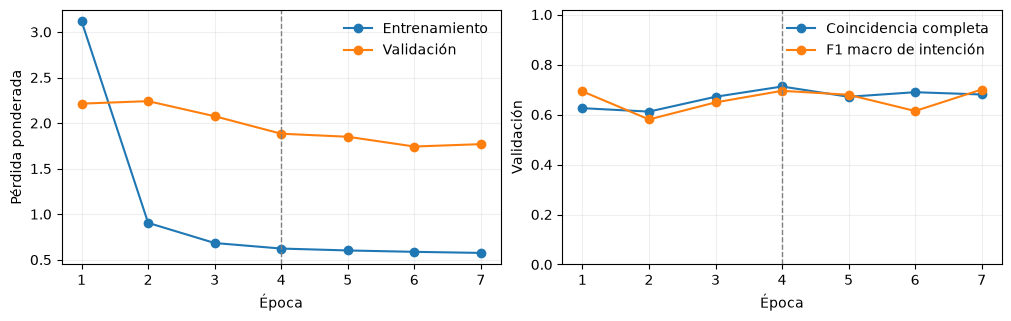

In [5]:
import matplotlib.pyplot as plt

historial = entrenamiento['history']
epocas = [item['epoch'] for item in historial]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), layout='constrained')
axes[0].plot(epocas, [item['train_loss'] for item in historial], 'o-', label='Entrenamiento')
axes[0].plot(epocas, [item['val_loss'] for item in historial], 'o-', label='Validación')
axes[0].set(xlabel='Época', ylabel='Pérdida ponderada')
axes[0].legend(frameon=False)
axes[1].plot(epocas, [item['exact_match'] for item in historial], 'o-', label='Coincidencia completa')
axes[1].plot(epocas, [item['intent_macro_f1'] for item in historial], 'o-', label='F1 macro de intención')
axes[1].set(xlabel='Época', ylabel='Validación', ylim=(0, 1.02))
axes[1].legend(frameon=False)
for ax in axes:
    ax.axvline(entrenamiento['selected_epoch'], color='gray', ls='--', lw=1)
    ax.grid(alpha=.2)
plt.show()

## 3. Comparar sobre frases reservadas

Los tres métodos reciben las mismas frases de cada prueba. La tabla usa el JSON posterior al filtro textual con umbral 0,70. Las propuestas tácticas erróneas se cuentan sobre todas las frases. La latencia B incluye el servidor local. Para medir Qwen en vivo, inicia llama.cpp y activa el interruptor correspondiente en la configuración.

In [6]:
modelo_c = get_model('C', configuracion.output)
informes = {}
for version in ('v1', 'v2'):
    for etiqueta in ('A', 'A reentrenada', 'B', 'C'):
        if etiqueta == 'C' and (VOLVER_A_MEDIR_A_C or REENTRENAR_C):
            informe = evaluate_rows(modelo_c, splits[f'test_{version}'], etiqueta)
        elif etiqueta == 'A' and VOLVER_A_MEDIR_A_C:
            informe = evaluate_rows(get_model(etiqueta), splits[f'test_{version}'], etiqueta)
        elif etiqueta == 'A reentrenada' and VOLVER_A_MEDIR_A_C:
            a_reentrenada = get_model('A', nlp / 'models/scratch-fase1.pt')
            informe = evaluate_rows(a_reentrenada, splits[f'test_{version}'], etiqueta)
        elif etiqueta == 'B' and MEDIR_QWEN_EN_VIVO:
            informe = evaluate_rows(get_model(etiqueta, llama_port=PUERTO_QWEN), splits[f'test_{version}'], etiqueta)
        else:
            ruta = resultados / f'evaluation-{etiqueta}-{version}.json'
            if etiqueta == 'A reentrenada':
                ruta = resultados / f'evaluation-A-reentrenado-{version}.json'
            if etiqueta == 'B' and version == 'v1':
                ruta = resultados.parent / 'evaluation-B.json'
            informe = json.loads(ruta.read_text(encoding='utf-8'))
        assert [(x['text'], x['expected']) for x in informe['predictions']] == [
            (item['text'], item['label']) for item in splits[f'test_{version}']
        ], f'El informe de {etiqueta} difiere de las filas reservadas {version}'
        informes[version, etiqueta] = informe

lineas = ['| Prueba | Modelo | n | JSON exacto | Orden exacta | F1 intención | F1 entidades | Orden errónea | p50 / p95 ms |',
          '|:--|:--|--:|--:|--:|--:|--:|--:|--:|']
for (version, etiqueta), informe in informes.items():
    m = informe['guarded']
    lineas.append(f"| {version} | {etiqueta} | {m['samples']} | {m['exact_match']:.1%} | "
                  f"{m['order_exact_match']:.1%} | {m['intent']['macro_f1']:.1%} | "
                  f"{m['normalized_entity_f1']:.1%} | {m['incorrect_order_proposal_rate']:.1%} | "
                  f"{m['median_ms']:.1f} / {m['p95_ms']:.1f} |")
display(Markdown('\n'.join(lineas)))

| Prueba | Modelo | n | JSON exacto | Orden exacta | F1 intención | F1 entidades | Orden errónea | p50 / p95 ms |
|:--|:--|--:|--:|--:|--:|--:|--:|--:|
| v1 | A | 172 | 12.2% | 8.8% | 23.3% | 20.5% | 2.3% | 2.4 / 4.9 |
| v1 | A reentrenada | 172 | 42.4% | 40.9% | 48.5% | 63.6% | 8.1% | 1.0 / 1.4 |
| v1 | B | 172 | 30.2% | 28.9% | 37.9% | 84.0% | 44.2% | 2120.2 / 3064.9 |
| v1 | C | 172 | 37.8% | 34.0% | 54.2% | 54.6% | 3.5% | 25.6 / 33.1 |
| v2 | A | 125 | 14.4% | 2.2% | 19.3% | 8.3% | 1.6% | 2.6 / 4.8 |
| v2 | A reentrenada | 125 | 36.0% | 27.0% | 46.0% | 48.8% | 5.6% | 1.0 / 1.5 |
| v2 | B | 125 | 47.2% | 36.0% | 70.7% | 94.1% | 35.2% | 2114.1 / 2514.6 |
| v2 | C | 125 | 49.6% | 40.4% | 57.9% | 65.0% | 6.4% | 23.8 / 30.7 |

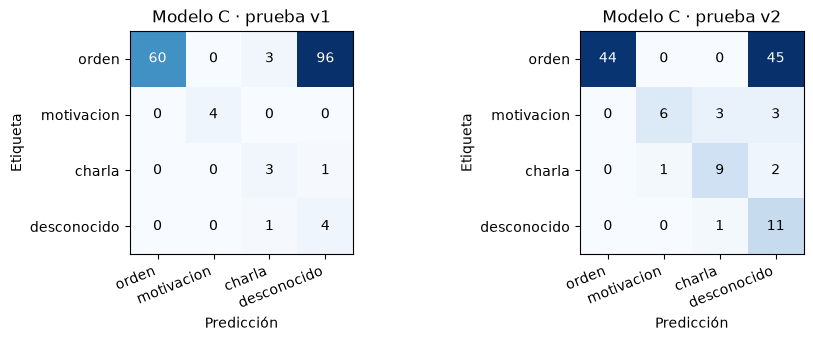

v1 · ECE 0.083 · Brier 0.164 · confianza de intención y acción
v2 · ECE 0.142 · Brier 0.197 · confianza de intención y acción


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout='constrained')
for ax, version in zip(axes, ('v1', 'v2')):
    matriz = informes[version, 'C']['guarded']['intent']['confusion']
    ax.imshow(matriz, cmap='Blues')
    for i, fila in enumerate(matriz):
        for j, conteo in enumerate(fila):
            ax.text(j, i, str(conteo), ha='center', va='center',
                    color='white' if conteo > max(map(max, matriz)) * .55 else 'black')
    ax.set_xticks(range(4), INTENTS, rotation=22, ha='right')
    ax.set_yticks(range(4), INTENTS)
    ax.set(xlabel='Predicción', ylabel='Etiqueta', title=f'Modelo C · prueba {version}')
plt.show()

for version in ('v1', 'v2'):
    c = informes[version, 'C']['calibration']
    print(f"{version} · ECE {c['ece']:.3f} · Brier {c['brier']:.3f} · confianza de intención y acción")

## 4. Probar frases nuevas

Edita la lista de frases y vuelve a ejecutar la celda. La propuesta se valida antes de presentar el comando. Los campos nulos quedan explícitos. Los destinatarios de ejemplo son los del catálogo de la prueba textual.

In [ ]:
UMBRAL_C = 0.70
FRASES = [
    'Alfa, avancen por el centro.',
    'Médicos, atiendan a Bravo en el centro.',
    'Charlie, retrocedan inmediatamente.',
    'Alfa, no avancen por el centro.',
    'Alfa, avancen por la derecha y después defiendan la base.',
    '¡Soldados, ustedes pueden con esto, vamos a ganar!',
    'Aquí el café sabe mejor con canela.',
    'Alfa, avancen por el flanco izquierdo.',
    'Eco, avancen por el flanco derecho',
    'Todos regresen a la base',
    'Todos al flanco izquierdo',
    'Vamos vamos avancen',
    'Vamos chicos ataquen',
    'Ya toca atacar muchachos vamos todos',
    'Atacar por el flanco izquierdo',
    'Ya vamos todos a atacar',
    'Adelante vamos',
    'Hola como estan',
    'Que tal '
]
for frase in FRASES:
    salida = evaluate_text(modelo_c, frase, aliases=UNITS, threshold=UMBRAL_C)
    print(frase)
    print(json.dumps(salida['command'], ensure_ascii=False))
    if salida['reason']:
        print(salida['reason'])
    print()

Alfa, avancen por el centro.
{"version": 1, "intent": "orden", "subject": {"type": "peloton", "name": "Alfa"}, "action": "avanzar", "location": {"id": "centro"}, "target": null, "model_confidence": 0.9896889925003052}

Médicos, atiendan a Bravo en el centro.
{"version": 1, "intent": "orden", "subject": {"type": "peloton", "name": "Médico"}, "action": "curar", "location": {"id": "centro"}, "target": {"type": "peloton", "name": "Bravo"}, "model_confidence": 0.9903258681297302}

Charlie, retrocedan inmediatamente.
{"version": 1, "intent": "orden", "subject": {"type": "peloton", "name": "Charlie"}, "action": "retirarse", "location": null, "target": null, "model_confidence": 0.9964073300361633}

Alfa, no avancen por el centro.
{"version": 1, "intent": "desconocido", "subject": null, "action": null, "location": null, "target": null, "model_confidence": 0.9984399676322937}

Alfa, avancen por la derecha y después defiendan la base.
{"version": 1, "intent": "desconocido", "subject": null, "acti

## 5. Delimitación de la entrega

Esta fase mide interpretación textual en español. El control de calidad de Push-to-Talk, Whisper con voz real y la integración del candidato C en Unreal pertenecen a las fases siguientes. La tasa de propuestas erróneas de esta tabla mide la salida textual, antes de la validación del mundo.